# Teaching SAM

## Setup

In [2]:
import os, glob, random
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from torch.utils.checkpoint import checkpoint

In [3]:
CFG = dict(
    root="CrackSeg", road_dir="CrackSeg/road_masks",
    hf_name="facebook/sam-vit-large",     # ViT-L matches D=1024, L=24; "facebook/sam-vit-base" to develop
    S=1024, P=16, Dl=64, tau=0.25,
    dens_k=15, pct=90, radius=50,         # paper values
    hf_thr=0.3, max_pts=32,               # ASSUMPTION (maps normalised to [0,1])
    hfc_mode="fft",                       # "fft" (paper) | "ridge" | "both"
    ridge="sato",                         # "sato" | "frangi" | "meijering"
    ridge_sigmas=(1, 2, 3),               # ASSUMPTION
    epochs=20, bs=2, lr=2e-4, min_lr=1e-7,
    use_prompts=True, use_hfc=True, grad_ckpt=True, out="runs/cracksam_hf",
)
S = CFG["S"]; device = "cuda"
N_HFC = {"fft": 1, "ridge": 1, "both": 2}[CFG["hfc_mode"]]
os.makedirs(CFG["out"], exist_ok=True); os.makedirs(CFG["road_dir"], exist_ok=True)
torch.manual_seed(0); np.random.seed(0); random.seed(0)

# Data

In [4]:
R = CFG["root"]

def pairs(img_dir, mask_dir):
    out = []
    for p in sorted(glob.glob(f"{img_dir}/*")):
        stem = os.path.splitext(os.path.basename(p))[0]
        m = glob.glob(f"{mask_dir}/{stem}.*")
        if m: out.append((p, m[0]))
    return out

train_all    = pairs(f"{R}/train/img", f"{R}/train/mask")
official_val = pairs(f"{R}/val/img",   f"{R}/val/mask")
test_images  = sorted(glob.glob(f"{R}/test/*"))          # unlabelled: qualitative results only

video_id = lambda p: os.path.basename(p).rsplit("_", 1)[0]  # "11_Trim_001744.jpg" -> "11_Trim"
vids = sorted({video_id(ip) for ip, _ in train_all}); random.Random(0).shuffle(vids)
val_vids, n = set(), 0
for v in vids:                                             # whole videos until ~10% of train
    if n >= 0.1 * len(train_all): break
    val_vids.add(v); n += sum(video_id(ip) == v for ip, _ in train_all)

splits = {
    "train": [x for x in train_all if video_id(x[0]) not in val_vids],
    "val":   [x for x in train_all if video_id(x[0]) in val_vids],
    "test":  official_val,
}
print({k: len(v) for k, v in splits.items()}, "| videos:", len(vids), "| unlabelled test:", len(test_images))

{'train': 2159, 'val': 319, 'test': 354} | videos: 17 | unlabelled test: 708


Road masks (run once)

In [5]:
from transformers import SegformerImageProcessor, SegformerForSemanticSegmentation
name = "nvidia/segformer-b5-finetuned-cityscapes-1024-1024" # substitute for Semantic-SAM
proc = SegformerImageProcessor.from_pretrained(name)
seg = SegformerForSemanticSegmentation.from_pretrained(name).to(device).eval()

Loading weights:   0%|          | 0/1172 [00:00<?, ?it/s]

In [6]:
@torch.no_grad()
def road_mask(img_rgb):
    x = proc(images=img_rgb, return_tensors="pt").to(device)
    lg = F.interpolate(seg(**x).logits, (S, S), mode="bilinear", align_corners=False)
    return (lg.argmax(1)[0]==0).cpu().numpy().astype(np.uint8)

In [7]:
for s in splits:
    for ip, _ in tqdm(splits[s], desc=s):
        dst = f"{CFG['road_dir']}/{os.path.splitext(os.path.basename(ip))[0]}.png"
        if not os.path.exists(dst):
            img = cv2.resize(cv2.cvtColor(cv2.imread(ip), cv2.COLOR_BGR2RGB), (S, S))
            cv2.imwrite(dst, road_mask(img)*255)

del seg
torch.cuda.empty_cache()

train:   0%|          | 0/2159 [00:00<?, ?it/s]

val:   0%|          | 0/319 [00:00<?, ?it/s]

test:   0%|          | 0/354 [00:00<?, ?it/s]

## FFT, ridge filter and loaders

In [8]:
from skimage import filters as skf

def high_freq(gray, tau):
    H, W = gray.shape
    Z = np.fft.fftshift(np.fft.fft2(gray, norm="forward"))
    line = int((H * W * tau)**0.5 // 2)
    Z[H//2-line:H//2+line, W//2-line:W//2+line] = 0
    return np.abs(np.fft.ifft2(np.fft.ifftshift(Z), norm="forward").real).astype(np.float32)

def ridge_map(gray):
    f = {"sato": skf.sato, "frangi": skf.frangi, "meijering": skf.meijering}[CFG["ridge"]]
    return f(gray, sigmas=CFG["ridge_sigmas"], black_ridges=True).astype(np.float32)

def norm_map(m, road): # ASSUMPTION: P99 inside road -> [0, 1]
    m = m * road
    v = m[road > 0]
    if v.size == 0:
        return np.zeros_like(m)
    return np.clip(m / (np.percentile(v, 99) + 1e-8), 0, 1).astype(np.float32)

def hfc_channels(gray, road):
    ch = []
    if CFG["hfc_mode"] in ("fft", "both"):
        ch.append(norm_map(high_freq(gray, CFG["tau"]), road))
    if CFG["hfc_mode"] in ("ridge", "both"):
        ch.append(norm_map(ridge_map(gray), road))
    ch = np.stack(ch)
    return ch, ch.mean(0)

def load_rgb(p):
    return cv2.resize(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB), (S, S))

def load_gt(p):
    return (cv2.resize(cv2.imread(p, 0), (S, S), interpolation=cv2.INTER_NEAREST) > 0).astype(np.uint8)

def load_road(ip):
    p = f"{CFG['road_dir']}/{os.path.splitext(os.path.basename(ip))[0]}.png"
    return (cv2.imread(p, 0) > 0).astype(np.uint8)

## Compare FFT and ridge

fft crack: 0.15951483 | other road: 0.12576105
ridge crack: 0.31557882 | other road: 0.11975355


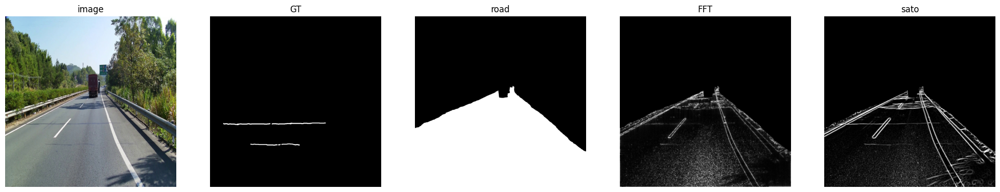

In [9]:
ip, mp = splits["train"][0]
img, gt, road = load_rgb(ip), load_gt(mp), load_road(ip)
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(np.float32) / 255
fft_m = norm_map(high_freq(gray, CFG["tau"]), road)
rdg_m = norm_map(ridge_map(gray), road)

fig, ax = plt.subplots(1, 5, figsize=(25, 5))
for a, (im, t) in zip(ax, [(img, "image"), (gt, "GT"), (road, "road"), (fft_m, "FFT"), (rdg_m, CFG["ridge"])]):
    a.imshow(im, cmap=None if im.ndim == 3 else "gray")
    a.set_title(t)
    a.axis("off")

for n, m in [("fft", fft_m), ('ridge', rdg_m)]:
    print(n, "crack:", m[gt > 0].mean(), "| other road:", m[(gt == 0) & (road > 0)].mean())

## Sparse prompt

(np.float64(-0.5), np.float64(1023.5), np.float64(1023.5), np.float64(-0.5))

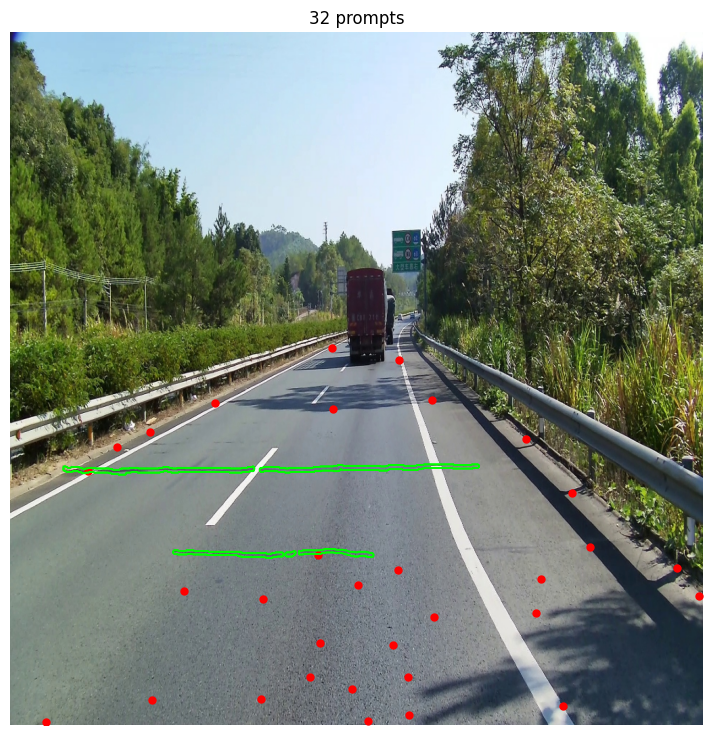

In [10]:
def sparse_prompts(hmap, rng):
    b = (hmap > CFG["hf_thr"]).astype(np.float32)
    k = CFG["dens_k"]
    dens = cv2.filter2D(b, -1, np.ones((k, k), np.float32), borderType=cv2.BORDER_CONSTANT)
    ys, xs = np.nonzero(b)
    if len(xs) == 0: return np.zeros((0, 2), np.float32)
    d = dens[ys, xs]
    keep = d <= np.percentile(d, CFG["pct"])          # ASSUMPTION: "sparser" = below P90
    ys, xs = ys[keep], xs[keep]
    chosen = []
    for j in rng.permutation(len(xs)):
        p = np.array([xs[j], ys[j]], np.float32)
        if all(np.hypot(*(p - q)) > CFG["radius"] for q in chosen):
            chosen.append(p)
            if len(chosen) >= CFG["max_pts"]: break
    return np.stack(chosen) if chosen else np.zeros((0, 2), np.float32)

_, pmap = hfc_channels(gray, road)
pts = sparse_prompts(pmap, np.random.default_rng(0))
plt.figure(figsize=(9, 9)); plt.imshow(img); plt.contour(gt, colors="lime", linewidths=0.8)
plt.scatter(pts[:, 0], pts[:, 1], c="red", s=25); plt.title(f"{len(pts)} prompts"); plt.axis("off")

## Dataset

In [11]:
from transformers import SamProcessor
sam_ip = SamProcessor.from_pretrained(CFG["hf_name"]).image_processor
MEAN = np.array(sam_ip.image_mean, np.float32) * 255
STD = np.array(sam_ip.image_std, np.float32) * 255
PAD = -10

In [12]:
class CrackDS(Dataset):
    def __init__(self, pairs, train):
        self.pairs = pairs
        self.train = train

    def __len__(self):
        return len(self.pairs)

    def aug(self, img, gt, road):
        if random.random() < 0.5:
            img, gt, road = img[:, ::-1], gt[:, ::-1], road[:, ::-1]
        if random.random() < 0.5:
            c = int(S * random.uniform(0.7, 1.0))
            y0, x0 = random.randint(0, S - c), random.randint(0, S - c)
            f = lambda a, it: cv2.resize(np.ascontiguousarray(a[y0:y0+c, x0:x0+c]), (S, S), interpolation=it)
            img, gt, road = f(img, cv2.INTER_LINEAR), f(gt, cv2.INTER_NEAREST), f(road, cv2.INTER_NEAREST)
        if random.random() < 0.5:                          # ASSUMPTION: ranges not given in the paper
            f = img.astype(np.float32)
            if random.random() < 0.5:                      # contrast: stretch around the image mean
                c = random.uniform(0.8, 1.2)
                f = (f - f.mean()) * c + f.mean()
            if random.random() < 0.5:                      # brightness: shift every pixel
                f = f + random.uniform(-20, 20)
            img = np.clip(f, 0, 255).astype(np.uint8)
        return [np.ascontiguousarray(a) for a in (img, gt, road)]

    def __getitem__(self, index):
        ip, mp = self.pairs[index]
        img, gt, road = load_rgb(ip), load_gt(mp), load_road(ip)
        if self.train:
            img, gt, road = self.aug(img, gt, road)
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(np.float32) / 255
        Ih, pmap = hfc_channels(gray, road)
        rng = np.random.default_rng() if self.train else np.random.default_rng(index)
        pts = sparse_prompts(pmap, rng) if CFG["use_prompts"] else np.zeros((0, 2), np.float32)
        K = CFG["max_pts"]
        Pt = np.zeros((K, 2), np.float32)
        Lb = np.full(K, PAD, np.int64)
        n = min(len(pts), K)
        Pt[:n] = pts[:n]
        Lb[:n] = 1
        x = torch.from_numpy(((img - MEAN) / STD).transpose(2, 0, 1)).float()
        return x, torch.from_numpy(Ih), torch.from_numpy(Pt), torch.from_numpy(Lb), torch.from_numpy(gt)[None].float()

mk = lambda s, tr: DataLoader(CrackDS(splits[s], tr), batch_size=CFG["bs"], shuffle=tr, num_workers=4, drop_last=tr)
train_dl, val_dl, test_dl = mk("train", True), mk("val", False), mk("test", False) 

## Model

In [13]:
from transformers import SamModel

def run_layer(layer, t):
    o = layer(t)
    return o[0] if isinstance(o, (tuple, list)) else o

In [14]:
class HFCEmbed(nn.Module):
    def __init__(self, Dl, in_ch):
        super().__init__()
        self.proj = nn.Conv2d(in_ch, Dl, CFG["P"], CFG["P"])
        self.pos = nn.Parameter(torch.zeros(1, S // CFG["P"], S // CFG["P"], Dl)) # ASSUMPTION: learnable
        nn.init.trunc_normal_(self.pos, std=0.02)
    def forward(self, Ih):
        return self.proj(Ih).permute(0, 2, 3, 1) + self.pos

In [15]:
class CrackSAM(nn.Module):
    def __init__(self):
        super().__init__()
        self.sam = SamModel.from_pretrained(CFG["hf_name"])
        enc = self.sam.vision_encoder
        self.D, self.L, Dl = enc.config.hidden_size, len(enc.layers), CFG["Dl"]
        self.hfc = HFCEmbed(Dl, N_HFC)
        self.ldp = nn.Linear(self.D, Dl)
        self.fc1 = nn.ModuleList([nn.Linear(Dl, Dl) for _ in range(self.L)])
        self.fc2 = nn.Linear(Dl, self.D)
        self.act = nn.GELU()

        for p in self.sam.parameters():
            p.requires_grad = False
        for p in self.sam.mask_decoder.parameters():
            p.requires_grad = True

    def encode(self, x, ih):
        enc = self.sam.vision_encoder
        t = enc.patch_embed(x)
        if enc.pos_embed is not None:
            t = t + enc.pos_embed
        e_in = self.ldp(t) + (self.hfc(ih) if CFG["use_hfc"] else 0)
        for i, layer in enumerate(enc.layers):
            t = checkpoint(run_layer, layer, t, use_reentrant=False) if (CFG["grad_ckpt"] and self.training) else run_layer(layer, t)
            t = t + self.fc2(self.act(self.fc1[i](e_in)))
        return enc.neck(t)

    def forward(self, x, Ih, Pt, Lb):
        out = self.sam(pixel_values=None, image_embeddings=self.encode(x, Ih),
                       input_points=Pt[:, None], input_labels=Lb[:, None], multimask_output=False)
        return F.interpolate(out.pred_masks[:, 0], (S, S), mode="bilinear", align_corners=False)

model = CrackSAM().to(device)

Loading weights:   0%|          | 0/482 [00:00<?, ?it/s]

In [16]:
n_adp = sum(p.numel() for p in model.fc1.parameters()) + sum(p.numel() for p in model.fc2.parameters())
D, L, Dl = model.D, model.L, CFG["Dl"]
print("adapter bytes:", n_adp * 4, "| Eq.7:", 4 * Dl * (L * Dl + L + D) + 4 * D)   # vit-large -> 665,600
print("trainable (M):", sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6)

model.eval()
with torch.no_grad():
    x0 = next(iter(val_dl))[0][:1].to(device); h0 = torch.zeros(1, N_HFC, S, S, device=device)
    ref = model.sam.vision_encoder(x0); ref = ref[0] if isinstance(ref, tuple) else ref.last_hidden_state
    w, b = model.fc2.weight.clone(), model.fc2.bias.clone()
    model.fc2.weight.zero_(); model.fc2.bias.zero_()
    mine = model.encode(x0, h0)
    model.fc2.weight.copy_(w); model.fc2.bias.copy_(b)
print("max diff vs HF encoder:", (mine - ref).abs().max().item())   # should be ~1e-4 or less

model.train()
x, Ih_t, Pt, Lb, y = [t.to(device) for t in next(iter(train_dl))]
out = model(x, Ih_t, Pt, Lb); print(out.shape)                       # (2,1,1024,1024)
F.binary_cross_entropy_with_logits(out, y).backward()
print("adapter grad:", model.fc1[0].weight.grad.abs().mean().item(),
      "| hfc grad:", model.hfc.proj.weight.grad.abs().mean().item(),
      "| GB:", torch.cuda.max_memory_allocated() / 1e9)
model.zero_grad()

adapter bytes: 665600 | Eq.7: 665600
trainable (M): 4.568932
max diff vs HF encoder: 0.0
torch.Size([2, 1, 1024, 1024])
adapter grad: 0.0010687840403988957 | hfc grad: 0.002377287484705448 | GB: 6.901499392


## Loss and metrics

In [18]:
from sklearn.metrics import average_precision_score, precision_recall_curve

def bce_dice(lg, t, eps=1.0):                 # ASSUMPTION: 1:1 weighting
    p = torch.sigmoid(lg); inter = (p * t).sum((1, 2, 3))
    dice = 1 - (2 * inter + eps) / (p.sum((1, 2, 3)) + t.sum((1, 2, 3)) + eps)
    return F.binary_cross_entropy_with_logits(lg, t) + dice.mean()

@torch.no_grad()
def evaluate(dl, sub=20000):
    model.eval(); cm = np.zeros((2, 2), np.int64); sc, lb = [], []; rng = np.random.default_rng(0)
    for x, Ih_t, Pt, Lb, y in tqdm(dl, leave=False):
        prob = torch.sigmoid(model(x.to(device), Ih_t.to(device), Pt.to(device), Lb.to(device))).cpu().numpy()
        for b in range(len(prob)):
            g = y[b, 0].numpy().astype(np.int64).ravel(); pr = prob[b, 0].ravel()
            cm += np.bincount(2 * g + (pr >= 0.5), minlength=4).reshape(2, 2)
            idx = rng.choice(g.size, sub, replace=False); sc.append(pr[idx]); lb.append(g[idx])
    tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    P, R = tp / (tp + fp + 1e-8), tp / (tp + fn + 1e-8)
    F1, IoU = 2 * P * R / (P + R + 1e-8), tp / (tp + fp + fn + 1e-8)
    sc, lb = np.concatenate(sc), np.concatenate(lb)
    return dict(mP=P.mean(), mR=R.mean(), mF1=F1.mean(), mIoU=IoU.mean(), crackIoU=IoU[1],
                AP=average_precision_score(lb, sc)), (sc, lb)

## Train

In [ ]:
params = [p for p in model.parameters() if p.requires_grad]
opt = torch.optim.AdamW(params, lr=CFG["lr"])
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, CFG["epochs"] * len(train_dl), eta_min=CFG["min_lr"])
TRAINED = lambda k: not k.startswith(("sam.vision_encoder", "sam.prompt_encoder", "sam.shared_image_embedding"))
best, hist = -1, []
for ep in range(CFG["epochs"]):
    model.train(); tot = 0
    for x, Ih_t, Pt, Lb, y in tqdm(train_dl, desc=f"ep{ep}"):
        x, Ih_t, Pt, Lb, y = [t.to(device) for t in (x, Ih_t, Pt, Lb, y)]
        loss = bce_dice(model(x, Ih_t, Pt, Lb), y)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step(); tot += loss.item()
    r, _ = evaluate(val_dl); r["loss"] = tot / len(train_dl); hist.append(r)
    print(ep, {k: round(float(v), 4) for k, v in r.items()})
    if r["mIoU"] > best:
        best = r["mIoU"]
        torch.save({k: v for k, v in model.state_dict().items() if TRAINED(k)}, f"{CFG['out']}/best.pt")

ep0:   0%|          | 0/1079 [00:00<?, ?it/s]

  0%|          | 0/160 [00:00<?, ?it/s]

0 {'mP': 0.746, 'mR': 0.7618, 'mF1': 0.7537, 'mIoU': 0.6683, 'crackIoU': 0.3425, 'AP': 0.5019, 'loss': 0.6945}


ep1:   0%|          | 0/1079 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x76595e90f4c0>
Traceback (most recent call last):
  File "/home/zhanglab/micromamba/envs/crack-seg/lib/python3.13/site-packages/torch/utils/data/dataloader.py", line 1686, in __del__
    self._shutdown_workers()
  File "/home/zhanglab/micromamba/envs/crack-seg/lib/python3.13/site-packages/torch/utils/data/dataloader.py", line 1669, in _shutdown_workers
    if w.is_alive():
  File "/home/zhanglab/micromamba/envs/crack-seg/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x76595e90f4c0>
Traceback (most recent call last):
  File "/home/zhanglab/micromamba/envs/crack-seg/lib/python3.13/site-packages/torch/utils/data/dataloader.py", line 1686, in __del__
    self._shutdown_workers()
  File "/home/zhanglab/mi

  0%|          | 0/160 [00:00<?, ?it/s]

... (26 outputs left out)

  0%|          | 0/160 [00:00<?, ?it/s]

9 {'mP': 0.7963, 'mR': 0.7389, 'mF1': 0.7645, 'mIoU': 0.6785, 'crackIoU': 0.3618, 'AP': 0.5139, 'loss': 0.5443}


ep10:   0%|          | 0/1079 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x76595e90f4c0>
Traceback (most recent call last):
  File "/home/zhanglab/micromamba/envs/crack-seg/lib/python3.13/site-packages/torch/utils/data/dataloader.py", line 1686, in __del__
    self._shutdown_workers()
  File "/home/zhanglab/micromamba/envs/crack-seg/lib/python3.13/site-packages/torch/utils/data/dataloader.py", line 1669, in _shutdown_workers
    Exception ignored in: if w.is_alive():
  File "/home/zhanglab/micromamba/envs/crack-seg/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    <function _MultiProcessingDataLoaderIter.__del__ at 0x76595e90f4c0>assert self._parent_pid == os.getpid(), 'can only test a child process'

Traceback (most recent call last):
AssertionError  File "/home/zhanglab/micromamba/envs/crack-seg/lib/python3.13/site-packages/torch/utils/data/dataloader.py", line 1686, in __del__
: can only test a child process    self._shutdown_workers()

  File "/home/zhanglab/mi

## Test

  0%|          | 0/177 [00:00<?, ?it/s]

{'mP': 0.8058, 'mR': 0.818, 'mF1': 0.8118, 'mIoU': 0.7255, 'crackIoU': 0.4553, 'AP': 0.608}


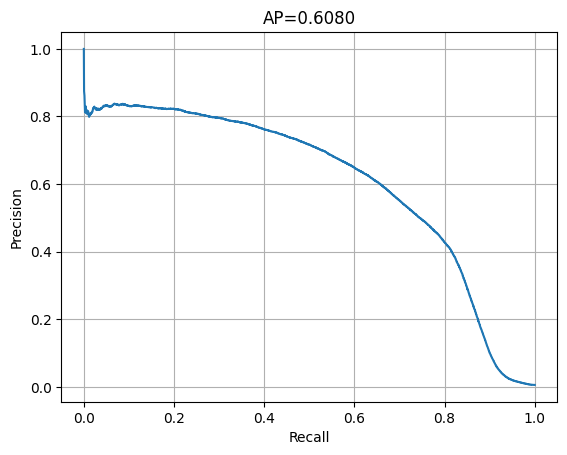

In [20]:
model.load_state_dict(torch.load(f"{CFG['out']}/best.pt"), strict=False)
res, (sc, lb) = evaluate(test_dl); print({k: round(float(v), 4) for k, v in res.items()})
p, r, _ = precision_recall_curve(lb, sc)

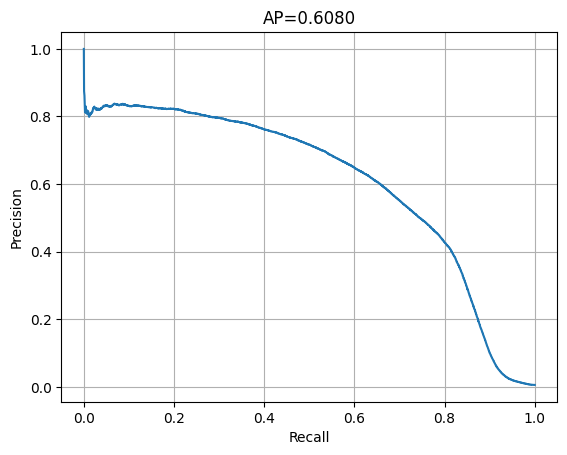

In [21]:
plt.plot(r, p)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"AP={res['AP']:.4f}")
plt.grid(True)
plt.show()

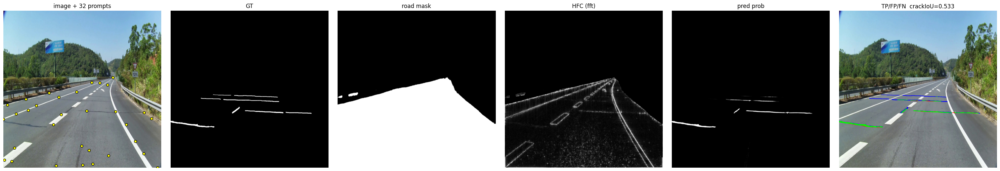

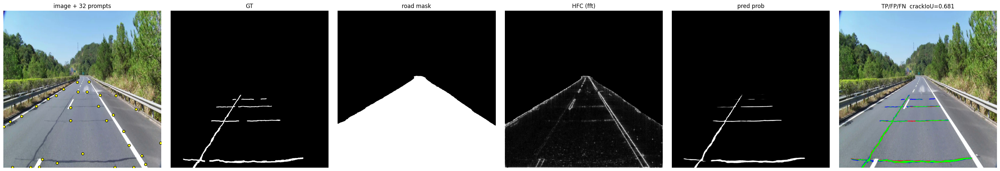

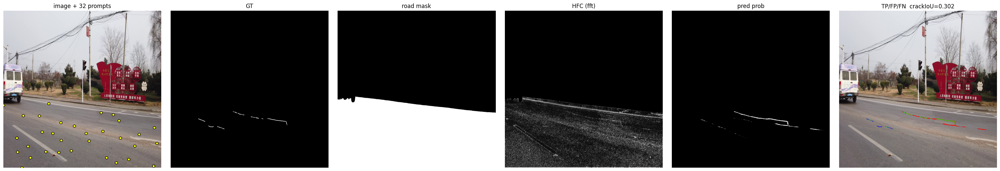

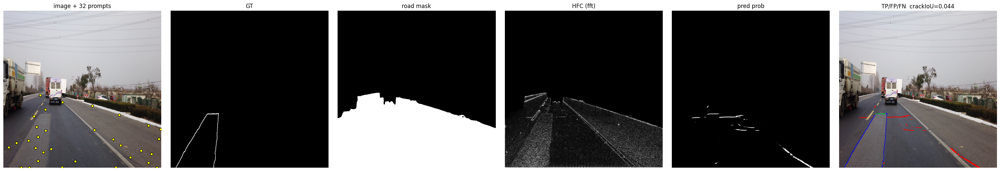

In [22]:
@torch.no_grad()
def show_examples(ds, idxs, thr=0.5):
    model.eval()
    for i in idxs:
        x, Ih, Pt, Lb, y = ds[i]
        prob = torch.sigmoid(model(x[None].to(device), Ih[None].to(device),
                                   Pt[None].to(device), Lb[None].to(device)))[0, 0].cpu().numpy()
        ip, _ = ds.pairs[i]
        img, road = load_rgb(ip), load_road(ip)            # un-normalised image for display
        gt, pred = y[0].numpy().astype(bool), prob >= thr
        pts = Pt[Lb == 1].numpy()

        tp, fp, fn = (pred & gt).sum(), (pred & ~gt).sum(), (~pred & gt).sum()
        iou = tp / max(tp + fp + fn, 1)

        over = img.copy()                                  # green = TP, red = FP, blue = FN
        over[pred & gt] = (0, 255, 0); over[pred & ~gt] = (255, 0, 0); over[~pred & gt] = (0, 0, 255)

        fig, ax = plt.subplots(1, 6, figsize=(30, 5))
        panels = [(img, "image + prompts"), (gt, "GT"), (road, "road mask"),
                  (Ih.mean(0).numpy(), f"HFC ({CFG['hfc_mode']})"), (prob, "pred prob"),
                  (over, f"TP/FP/FN  crackIoU={iou:.3f}")]
        for a, (im, t) in zip(ax, panels):
            a.imshow(im, cmap=None if im.ndim == 3 else "gray", vmin=0, vmax=1 if im.ndim == 2 else None)
            a.set_title(t); a.axis("off")
        ax[0].scatter(pts[:, 0], pts[:, 1], c="yellow", s=30, edgecolors="black")
        ax[0].set_title(f"image + {len(pts)} prompts")
        plt.tight_layout(); plt.show()

val_ds = CrackDS(splits["val"], False)
show_examples(val_ds, [0, 10, 50, 100])

  0%|          | 0/160 [00:00<?, ?it/s]

319 images with cracks (0 without) | mean per-image crackIoU 0.368 | median 0.388


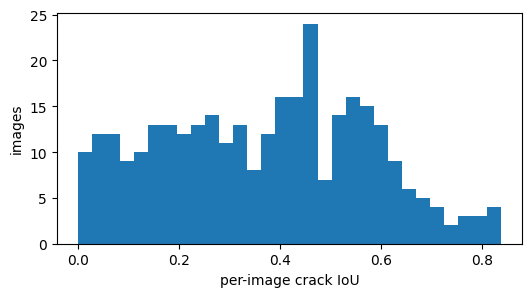

--- quantile 0.00: index 74, crackIoU 0.000, DJI_0198_001611.jpg


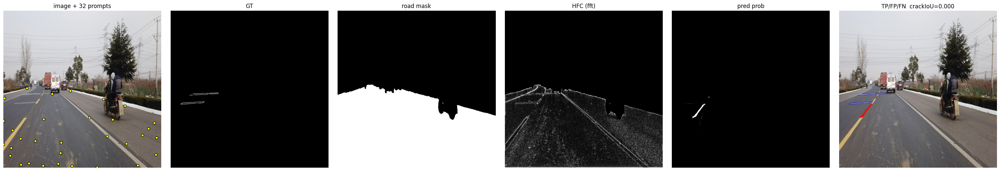

--- quantile 0.10: index 198, crackIoU 0.081, DJI_0198_005566.jpg


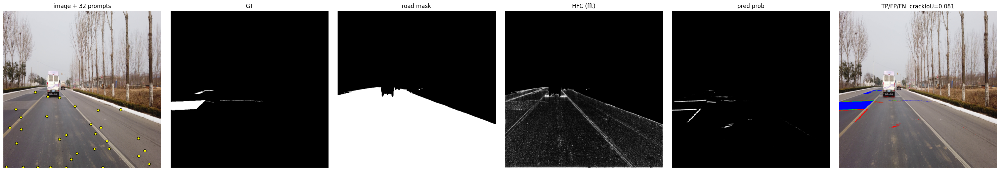

--- quantile 0.25: index 228, crackIoU 0.205, DJI_0198_007666.jpg


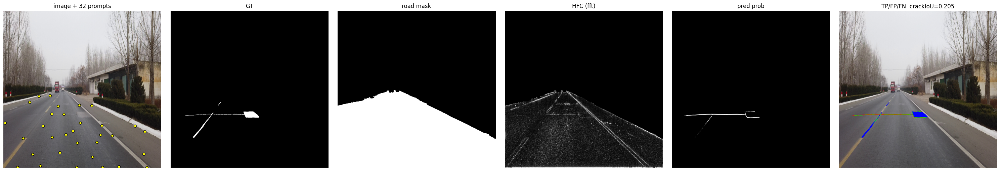

--- quantile 0.50: index 219, crackIoU 0.388, DJI_0198_007339.jpg


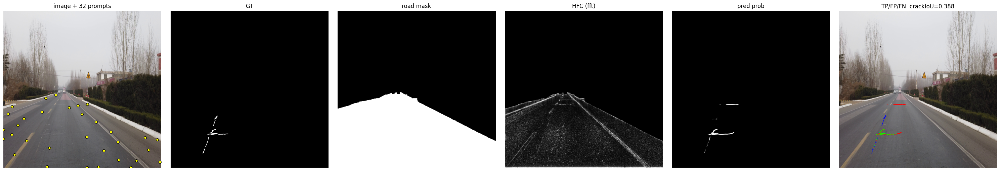

--- quantile 0.75: index 204, crackIoU 0.528, DJI_0198_005823.jpg


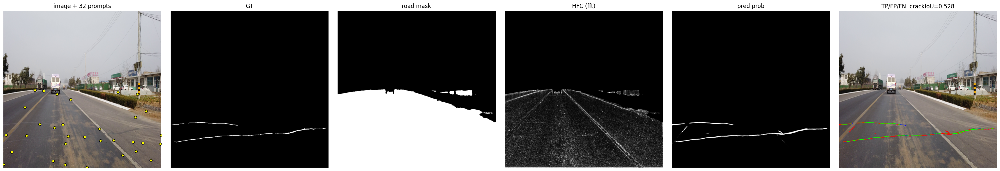

--- quantile 0.90: index 6, crackIoU 0.622, 202210281429_004706.jpg


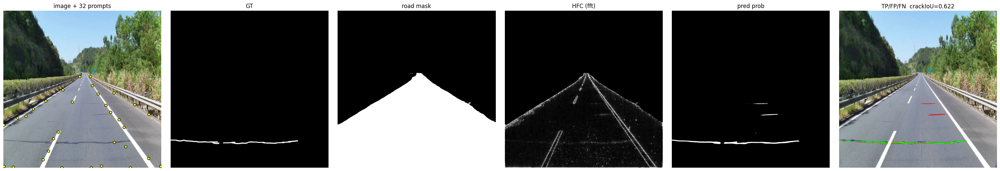

--- quantile 1.00: index 30, crackIoU 0.837, 202210281429_005990.jpg


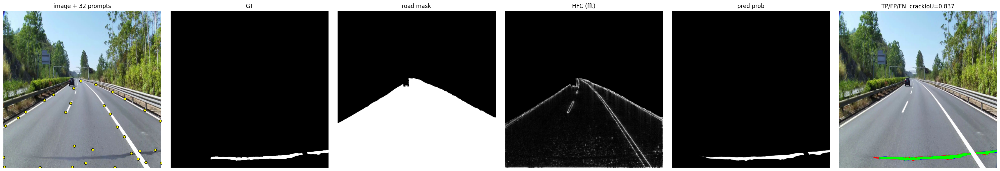

In [23]:
@torch.no_grad()
def per_image_iou(ds, thr=0.5):
    model.eval(); ious = []
    dl = DataLoader(ds, batch_size=CFG["bs"], shuffle=False, num_workers=4)
    for x, Ih_t, Pt, Lb, y in tqdm(dl, leave=False):
        prob = torch.sigmoid(model(x.to(device), Ih_t.to(device), Pt.to(device), Lb.to(device))).cpu()
        pred, gt = prob >= thr, y.bool()
        tp = (pred & gt).sum((1, 2, 3)).float(); fp = (pred & ~gt).sum((1, 2, 3)).float(); fn = (~pred & gt).sum((1, 2, 3)).float()
        iou = tp / (tp + fp + fn).clamp(min=1)
        iou[gt.sum((1, 2, 3)) == 0] = float("nan")         # no crack in GT -> IoU undefined
        ious += iou.tolist()
    return np.array(ious)

def show_quantiles(ds, qs=(0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0), thr=0.5):
    ious = per_image_iou(ds, thr)
    valid = np.where(~np.isnan(ious))[0]
    order = valid[np.argsort(ious[valid])]                  # worst -> best
    print(f"{len(valid)} images with cracks ({len(ious) - len(valid)} without) | "
          f"mean per-image crackIoU {np.nanmean(ious):.3f} | median {np.nanmedian(ious):.3f}")
    plt.figure(figsize=(6, 3)); plt.hist(ious[valid], bins=30); plt.xlabel("per-image crack IoU"); plt.ylabel("images"); plt.show()
    for q in qs:
        i = order[int(round(q * (len(order) - 1)))]
        print(f"--- quantile {q:.2f}: index {i}, crackIoU {ious[i]:.3f}, {os.path.basename(ds.pairs[i][0])}")
        show_examples(ds, [i], thr)
    return ious

val_ds = CrackDS(splits["val"], False)
ious = show_quantiles(val_ds)

## Sensitivity Test

Check if SAM has to use points prompt.

In [24]:
CFG["use_prompts"] = False                # dataset now returns all-PAD points
r_noprompt, _ = evaluate(DataLoader(CrackDS(splits["val"], False), batch_size=CFG["bs"], num_workers=4))
CFG["use_prompts"] = True
r_prompt, _ = evaluate(DataLoader(CrackDS(splits["val"], False), batch_size=CFG["bs"], num_workers=4))
print("with prompts:", r_prompt["crackIoU"], "| without:", r_noprompt["crackIoU"])

  0%|          | 0/160 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7af403d59120>
Traceback (most recent call last):
  File "/home/zhanglab/micromamba/envs/crack-seg/lib/python3.13/site-packages/torch/utils/data/dataloader.py", line 1686, in __del__
    self._shutdown_workers()
  File "/home/zhanglab/micromamba/envs/crack-seg/lib/python3.13/site-packages/torch/utils/data/dataloader.py", line 1669, in _shutdown_workers
    if w.is_alive():
  File "/home/zhanglab/micromamba/envs/crack-seg/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7af403d59120>
Traceback (most recent call last):
  File "/home/zhanglab/micromamba/envs/crack-seg/lib/python3.13/site-packages/torch/utils/data/dataloader.py", line 1686, in __del__
    self._shutdown_workers()
  File "/home/zhanglab/mi

  0%|          | 0/160 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7af403d59120>
Traceback (most recent call last):
  File "/home/zhanglab/micromamba/envs/crack-seg/lib/python3.13/site-packages/torch/utils/data/dataloader.py", line 1686, in __del__
    self._shutdown_workers()
  File "/home/zhanglab/micromamba/envs/crack-seg/lib/python3.13/site-packages/torch/utils/data/dataloader.py", line 1669, in _shutdown_workers
    if w.is_alive():Exception ignored in: 
  File "/home/zhanglab/micromamba/envs/crack-seg/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    <function _MultiProcessingDataLoaderIter.__del__ at 0x7af403d59120>assert self._parent_pid == os.getpid(), 'can only test a child process'

Traceback (most recent call last):
AssertionError  File "/home/zhanglab/micromamba/envs/crack-seg/lib/python3.13/site-packages/torch/utils/data/dataloader.py", line 1686, in __del__
:     can only test a child processself._shutdown_workers()

  File "/home/zhanglab/mi

with prompts: 0.3678968978791926 | without: 0.3751403847799121


In [25]:
@torch.no_grad()
def prompt_hit_rate(ds, n=100, thr=0.5):
    model.eval(); on_pred = on_gt = tot = 0
    for i in range(min(n, len(ds))):
        x, Ih, Pt, Lb, y = ds[i]
        prob = torch.sigmoid(model(x[None].to(device), Ih[None].to(device), Pt[None].to(device), Lb[None].to(device)))[0, 0].cpu().numpy()
        pts = Pt[Lb == 1].numpy().astype(int)
        if len(pts) == 0: continue
        pred = cv2.dilate((prob >= thr).astype(np.uint8), np.ones((11, 11), np.uint8))   # within ~5 px
        gt = cv2.dilate(y[0].numpy().astype(np.uint8), np.ones((11, 11), np.uint8))
        on_pred += pred[pts[:, 1], pts[:, 0]].sum(); on_gt += gt[pts[:, 1], pts[:, 0]].sum(); tot += len(pts)
    print(f"prompts near a GT crack: {on_gt / tot:.2%} | near a predicted crack: {on_pred / tot:.2%}")
prompt_hit_rate(CrackDS(splits["val"], False))

prompts near a GT crack: 4.50% | near a predicted crack: 5.03%


### Assumption (Load from the checkpoint that trained only 10 epochs)
**Observation**. Removing the prompt points at inference does not reduce performance (crack IoU 36.79% with prompts vs. 37.51% without). Only 4.50% of the generated prompts lie within 5 px of a ground-truth crack, and 5.03% lie within 5 px of a predicted crack. Thus the trained model does not rely on the prompts, and the prompts themselves are mostly placed off-crack.

**Interpretation**. In our reproduction, the sparse prompt generator does not localise cracks: about 95% of the points fall on non-crack regions, likely because of unspecified details we had to assume (the binarisation threshold for the high-frequency map, its normalisation, and the road mask from SegFormer instead of Semantic Segment Anything). The fine-tuned mask decoder appears to learn to ignore these uninformative prompts. This does not by itself show that prompts are unnecessary in the original method. That would require a retrained no-prompt ablation and a prompt generator whose points actually land on cracks.

In [26]:
ds = CrackDS(splits["train"][:100], False)
for thr in (0.3, 0.5, 0.7, 0.9):
    CFG["hf_thr"] = thr; hit = tot = 0
    for i in range(len(ds)):
        _, _, Pt, Lb, y = ds[i]; pts = Pt[Lb == 1].numpy().astype(int)
        if len(pts) == 0: continue
        g = cv2.dilate(y[0].numpy().astype(np.uint8), np.ones((11, 11), np.uint8))
        hit += g[pts[:, 1], pts[:, 0]].sum(); tot += len(pts)
    print(f"hf_thr={thr}: {tot} prompts, {hit / max(tot, 1):.2%} near GT")
CFG["hf_thr"] = 0.3

hf_thr=0.3: 3200 prompts, 2.84% near GT
hf_thr=0.5: 3200 prompts, 2.09% near GT
hf_thr=0.7: 3200 prompts, 2.00% near GT
hf_thr=0.9: 3200 prompts, 1.88% near GT
